# Taller Lagos y Ríos
## Lago Chinchaycocha (Junín) desde el espacio · 2016–2026

**¿Qué vamos a hacer?**
1. Medir el **área del lago** cada año con imágenes **Landsat 8 y 9** (índice MNDWI).
2. Traer la **lluvia** (CHIRPS) y la **temperatura y evaporación** (ERA5‑Land) de la cuenca.
3. Leer los resultados con el enfoque del **ciclo hidrológico**: ¿el lago pierde superficie cuando llueve menos y hace más calor (El Niño)?


### Paso 1 · Escribe el ID de tu proyecto de Google Cloud
Lo ves en https://code.earthengine.google.com (arriba a la derecha) o en https://console.cloud.google.com.

In [1]:
PROJECT_ID = "streamlittest-453315"

###  Paso 2 · Conectarnos a Google Earth Engine

In [2]:
import ee
import pandas as pd
import matplotlib.pyplot as plt

ee.Authenticate()                 # se abre una ventana: acepta con tu cuenta Google
ee.Initialize(project=PROJECT_ID)
print("✅ Conectado a Earth Engine")

✅ Conectado a Earth Engine


###  Paso 3 · Zona de estudio
- **Caja**: rectángulo que encierra al lago.
- **Zona del lago**: píxeles que alguna vez fueron agua entre 1984 y 2021 (JRC Global Surface Water). Así evitamos confundir sombras de cerros con agua.
- **Cuenca**: área que drena hacia el lago (HydroBASINS). Ahí mediremos la lluvia.

In [3]:
ANIO_INICIO, ANIO_FIN = 2016, 2026
MES_SECO_INI, MES_SECO_FIN = 6, 9      # junio a setiembre (época seca, pocas nubes)
UMBRAL_MNDWI = 0                       # MNDWI > 0 → agua

caja = ee.Geometry.Rectangle([-76.30, -11.25, -75.90, -10.80])
centro_lago = ee.Geometry.Point([-76.10, -11.02])

zona_lago = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("max_extent").eq(1).clip(caja)
cuenca = ee.FeatureCollection("WWF/HydroSHEDS/v1/Basins/hybas_7").filterBounds(centro_lago).geometry()

print("Área de la cuenca aportante:", round(cuenca.area(1000).getInfo() / 1e6), "km²")

Área de la cuenca aportante: 10701 km²


### Paso 4 · Imágenes Landsat 8 + 9: quitar nubes y calcular MNDWI
**MNDWI = (Verde − SWIR1) / (Verde + SWIR1)**
El agua refleja algo de verde pero casi nada de infrarrojo de onda corta (SWIR) → MNDWI positivo.

In [4]:
def preparar_landsat(img):
    qa = img.select("QA_PIXEL")
    # bits: 1 nube dilatada, 3 nube, 4 sombra, 5 nieve
    malo = (qa.bitwiseAnd(1 << 1).neq(0)
            .Or(qa.bitwiseAnd(1 << 3).neq(0))
            .Or(qa.bitwiseAnd(1 << 4).neq(0))
            .Or(qa.bitwiseAnd(1 << 5).neq(0)))
    refl = img.select("SR_B.").multiply(0.0000275).add(-0.2)       # a reflectancia 0–1
    mndwi = refl.normalizedDifference(["SR_B3", "SR_B6"]).rename("MNDWI")
    return refl.addBands(mndwi).updateMask(malo.Not()).copyProperties(img, ["system:time_start"])

landsat = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
           .merge(ee.ImageCollection("LANDSAT/LC09/C02/T1_L2"))
           .filterBounds(caja)
           .filter(ee.Filter.calendarRange(ANIO_INICIO, ANIO_FIN, "year"))
           .filter(ee.Filter.calendarRange(MES_SECO_INI, MES_SECO_FIN, "month"))
           .map(preparar_landsat))

print("Imágenes Landsat en época seca:", landsat.size().getInfo())

Imágenes Landsat en época seca: 237


###  Paso 5 · Área del lago por año (km²)

In [5]:
def area_del_anio(anio):
    anio = ee.Number(anio)
    col = landsat.filter(ee.Filter.calendarRange(anio, anio, "year"))
    agua = col.select("MNDWI").median().gt(UMBRAL_MNDWI).And(zona_lago)
    area = (agua.multiply(ee.Image.pixelArea()).divide(1e6)
            .reduceRegion(reducer=ee.Reducer.sum(), geometry=caja, scale=30, maxPixels=1e10)
            .get("MNDWI"))
    return ee.Feature(None, {"anio": anio, "area_km2": area, "n_imagenes": col.size()})

anios = ee.List.sequence(ANIO_INICIO, ANIO_FIN)
tabla_area = ee.FeatureCollection(anios.map(area_del_anio)).getInfo()

df_area = pd.DataFrame([f["properties"] for f in tabla_area["features"]])
df_area["anio"] = df_area["anio"].astype(int)
df_area["area_km2"] = df_area["area_km2"].round(1)
df_area

,anio,area_km2,n_imagenes
0,2016,224.0,16
1,2017,225.8,13
2,2018,218.8,14
3,2019,191.6,14
4,2020,225.3,16
5,2021,224.0,16
6,2022,219.7,31
7,2023,206.9,30
8,2024,214.7,28
9,2025,220.3,31


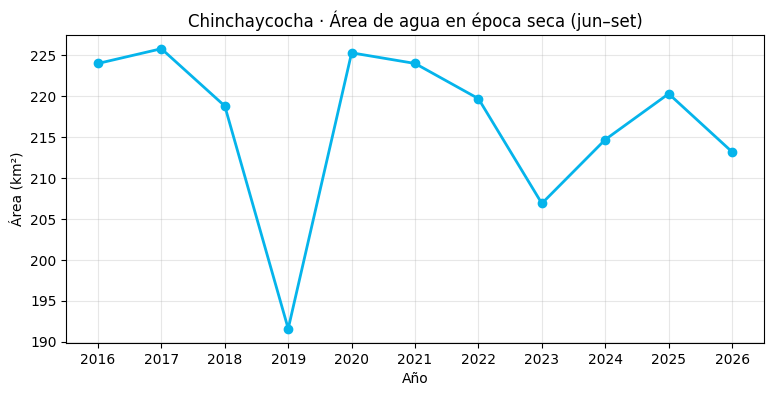

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(df_area["anio"], df_area["area_km2"], "o-", color="#05B4EB", lw=2)
plt.title("Chinchaycocha · Área de agua en época seca (jun–set)")
plt.xlabel("Año"); plt.ylabel("Área (km²)"); plt.grid(alpha=0.3)
plt.xticks(df_area["anio"])
plt.show()


In [8]:
# evaluación de perdida de nivel de área
perdida = df_area["area_km2"].max() - df_area["area_km2"].min()
print(f"Año con MÁS agua:   {df_area.loc[df_area.area_km2.idxmax(), 'anio']}")
print(f"Año con MENOS agua: {df_area.loc[df_area.area_km2.idxmin(), 'anio']}")
print(f"Diferencia entre ambos: {perdida:.1f} km²")

Año con MÁS agua:   2017
Año con MENOS agua: 2019
Diferencia entre ambos: 34.2 km²


### Paso 6 · Ver el lago: color real vs. agua detectada
Compara un año "normal" con un año seco. Puedes cambiar los años de la lista si quieres.

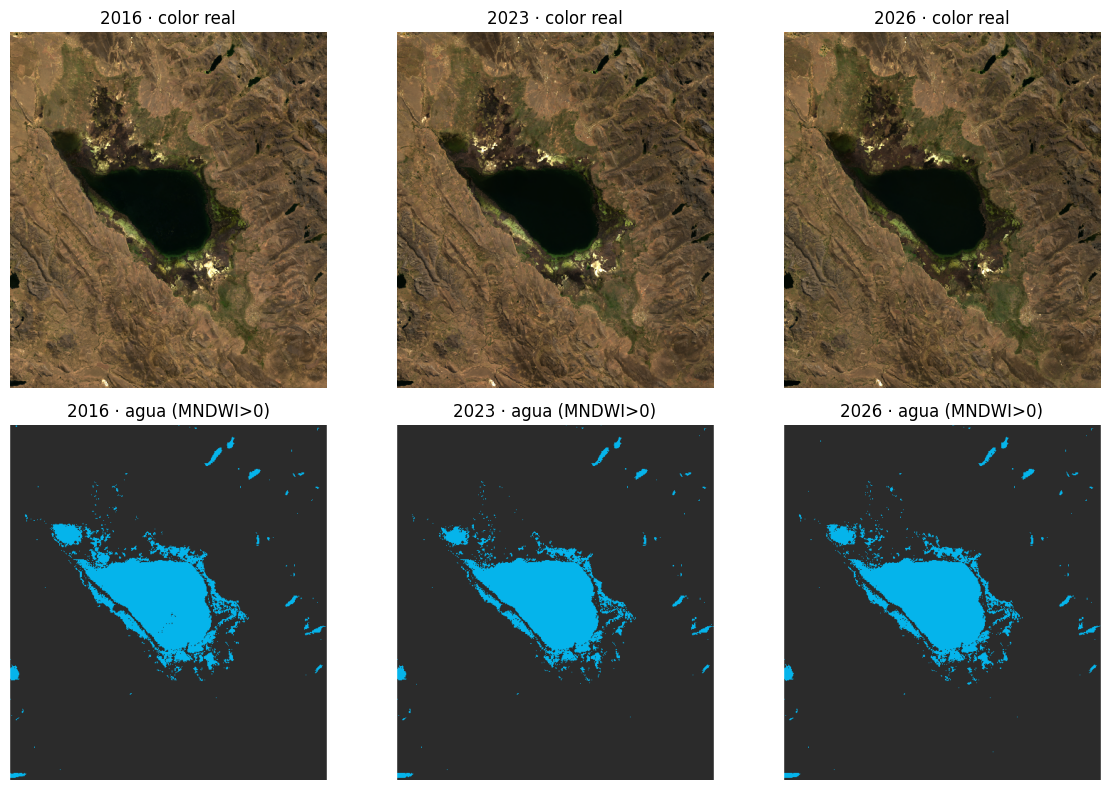

In [9]:
from PIL import Image
import requests, io

def foto(anio, tipo="rgb"):
    col = landsat.filter(ee.Filter.calendarRange(anio, anio, "year"))
    if tipo == "rgb":
        img = col.select(["SR_B4", "SR_B3", "SR_B2"]).median().visualize(min=0, max=0.25)
    else:
        img = (col.select("MNDWI").median().gt(UMBRAL_MNDWI).And(zona_lago)
               .visualize(min=0, max=1, palette=["#2B2B2B", "#05B4EB"]))
    url = img.getThumbURL({"region": caja, "dimensions": 500, "format": "png"})
    return Image.open(io.BytesIO(requests.get(url).content))

anios_ver = [2016, 2023, 2026]
fig, ax = plt.subplots(2, len(anios_ver), figsize=(4 * len(anios_ver), 8))
for i, a in enumerate(anios_ver):
    ax[0, i].imshow(foto(a, "rgb"));  ax[0, i].set_title(f"{a} · color real")
    ax[1, i].imshow(foto(a, "agua")); ax[1, i].set_title(f"{a} · agua (MNDWI>0)")
    ax[0, i].axis("off"); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

### Paso 7 · El ciclo hidrológico: lluvia, temperatura y evaporación
Usamos el **año hidrológico** (setiembre a agosto). Ejemplo: el año hidrológico **2024** = set‑2023 → ago‑2024, que son las lluvias que llenan el lago **antes** de la época seca de 2024.

| Insumo | Variable | Resolución |
|---|---|---|
| CHIRPS (satélite + estaciones) | Lluvia | ~5 km, diario |
| ERA5‑Land (reanálisis ECMWF) | Lluvia, temperatura, evaporación | ~11 km, mensual |

In [10]:
chirps = ee.ImageCollection("UCSB-CHG/CHIRPS/DAILY")
era5 = ee.ImageCollection("ECMWF/ERA5_LAND/MONTHLY_AGGR")

def promedio_cuenca(img, banda, escala):
    return img.reduceRegion(reducer=ee.Reducer.mean(), geometry=cuenca, scale=escala).get(banda)

def clima_del_anio(anio):
    anio = ee.Number(anio)
    ini = ee.Date.fromYMD(anio.subtract(1), 9, 1)
    fin = ee.Date.fromYMD(anio, 9, 1)
    e5 = era5.filterDate(ini, fin)
    return ee.Feature(None, {
        "anio": anio,
        "lluvia_CHIRPS_mm": promedio_cuenca(chirps.filterDate(ini, fin).select("precipitation").sum(), "precipitation", 5000),
        "lluvia_ERA5_mm":   promedio_cuenca(e5.select("total_precipitation_sum").sum().multiply(1000), "total_precipitation_sum", 11000),
        "evap_ERA5_mm":     promedio_cuenca(e5.select("total_evaporation_sum").sum().multiply(-1000), "total_evaporation_sum", 11000),
        "temp_C":           promedio_cuenca(e5.select("temperature_2m").mean().subtract(273.15), "temperature_2m", 11000),
        "meses_ERA5": e5.size(),
    })

tabla_clima = ee.FeatureCollection(anios.map(clima_del_anio)).getInfo()
df_clima = pd.DataFrame([f["properties"] for f in tabla_clima["features"]])
df_clima["anio"] = df_clima["anio"].astype(int)
df_clima = df_clima.round(1)
print("⚠️ Si 'meses_ERA5' < 12, ese año todavía no está completo en ERA5-Land (tiene ~2–3 meses de retraso).")
df_clima

⚠️ Si 'meses_ERA5' < 12, ese año todavía no está completo en ERA5-Land (tiene ~2–3 meses de retraso).


,anio,evap_ERA5_mm,lluvia_CHIRPS_mm,lluvia_ERA5_mm,meses_ERA5,temp_C
0,2016,902.6,649.5,1523.4,12,5.2
1,2017,848.2,726.0,1772.0,12,4.7
2,2018,845.2,788.9,1723.2,12,4.3
3,2019,844.3,871.0,1623.6,12,4.8
4,2020,849.5,728.0,1617.6,12,4.9
5,2021,857.1,781.0,1615.3,12,4.5
6,2022,856.2,807.8,1625.8,12,4.7
7,2023,856.2,751.2,1474.1,12,4.8
8,2024,874.3,673.1,1766.8,12,5.6
9,2025,836.7,799.0,1815.2,12,4.9


###  Paso 8 · ¿Qué tan confiables son los insumos de lluvia?
CHIRPS y ERA5‑Land estiman la lluvia de forma distinta. En los Andes los reanálisis suelen **sobreestimar** la lluvia. Comparemos ambos antes de sacar conclusiones.

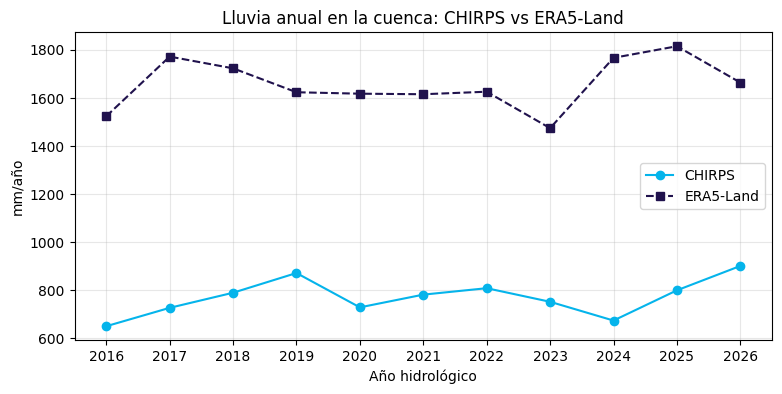

ERA5-Land da en promedio +117% de lluvia respecto a CHIRPS
Correlación entre ambos: 0.09


In [11]:
plt.figure(figsize=(9, 4))
plt.plot(df_clima["anio"], df_clima["lluvia_CHIRPS_mm"], "o-", label="CHIRPS", color="#05B4EB")
plt.plot(df_clima["anio"], df_clima["lluvia_ERA5_mm"], "s--", label="ERA5-Land", color="#20124D")
plt.title("Lluvia anual en la cuenca: CHIRPS vs ERA5-Land")
plt.xlabel("Año hidrológico"); plt.ylabel("mm/año"); plt.legend(); plt.grid(alpha=0.3)
plt.xticks(df_clima["anio"]); plt.show()

dif = (df_clima["lluvia_ERA5_mm"] - df_clima["lluvia_CHIRPS_mm"]) / df_clima["lluvia_CHIRPS_mm"] * 100
print(f"ERA5-Land da en promedio {dif.mean():+.0f}% de lluvia respecto a CHIRPS")
print(f"Correlación entre ambos: {df_clima['lluvia_CHIRPS_mm'].corr(df_clima['lluvia_ERA5_mm']):.2f}")

###  Paso 9 · Juntamos todo: área del lago vs lluvia y temperatura

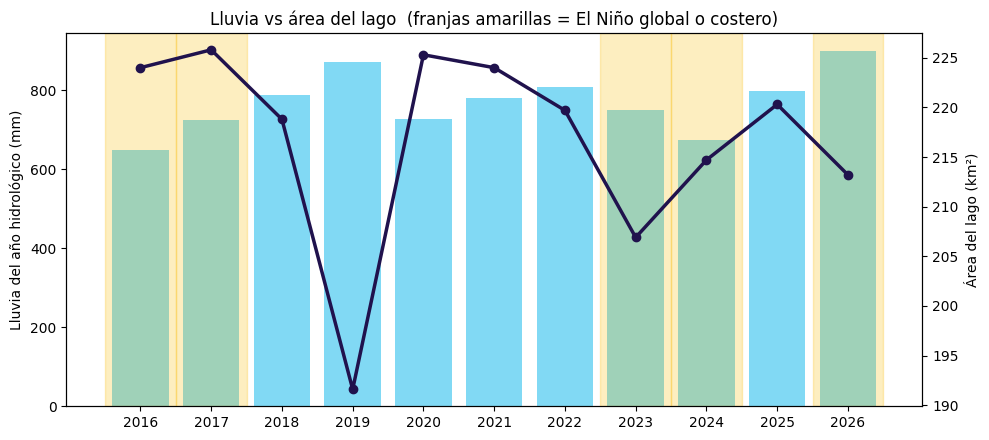

In [13]:
df = df_area.merge(df_clima, on="anio")
df["anomalia_lluvia_%"] = ((df["lluvia_CHIRPS_mm"] / df["lluvia_CHIRPS_mm"].mean() - 1) * 100).round(0)
df["anomalia_temp_C"]   = (df["temp_C"] - df["temp_C"].mean()).round(2)
df["balance_P_menos_E_mm"] = (df["lluvia_CHIRPS_mm"] - df["evap_ERA5_mm"]).round(0)

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(df["anio"], df["lluvia_CHIRPS_mm"], color="#05B4EB", alpha=0.5, label="Lluvia (CHIRPS)")
ax1.set_ylabel("Lluvia del año hidrológico (mm)")
ax2 = ax1.twinx()
ax2.plot(df["anio"], df["area_km2"], "o-", color="#20124D", lw=2.5, label="Área del lago")
ax2.set_ylabel("Área del lago (km²)")
for a in [2016, 2017, 2023, 2024, 2026]:   # años con El Niño (global o costero)
    if a in list(df["anio"]):
        ax1.axvspan(a - 0.5, a + 0.5, color="#FBBC05", alpha=0.25)
plt.title("Lluvia vs área del lago  (franjas amarillas = El Niño global o costero)")
plt.xticks(df["anio"]); fig.tight_layout(); plt.show()



In [14]:
df[["anio", "area_km2", "lluvia_CHIRPS_mm", "anomalia_lluvia_%", "temp_C", "anomalia_temp_C", "evap_ERA5_mm", "balance_P_menos_E_mm"]]

,anio,area_km2,lluvia_CHIRPS_mm,anomalia_lluvia_%,temp_C,anomalia_temp_C,evap_ERA5_mm,balance_P_menos_E_mm
0,2016,224.0,649.5,-16.0,5.2,0.36,902.6,-253.0
1,2017,225.8,726.0,-6.0,4.7,-0.14,848.2,-122.0
2,2018,218.8,788.9,2.0,4.3,-0.54,845.2,-56.0
3,2019,191.6,871.0,13.0,4.8,-0.04,844.3,27.0
4,2020,225.3,728.0,-6.0,4.9,0.06,849.5,-122.0
5,2021,224.0,781.0,1.0,4.5,-0.34,857.1,-76.0
6,2022,219.7,807.8,5.0,4.7,-0.14,856.2,-48.0
7,2023,206.9,751.2,-3.0,4.8,-0.04,856.2,-105.0
8,2024,214.7,673.1,-13.0,5.6,0.76,874.3,-201.0
9,2025,220.3,799.0,4.0,4.9,0.06,836.7,-38.0


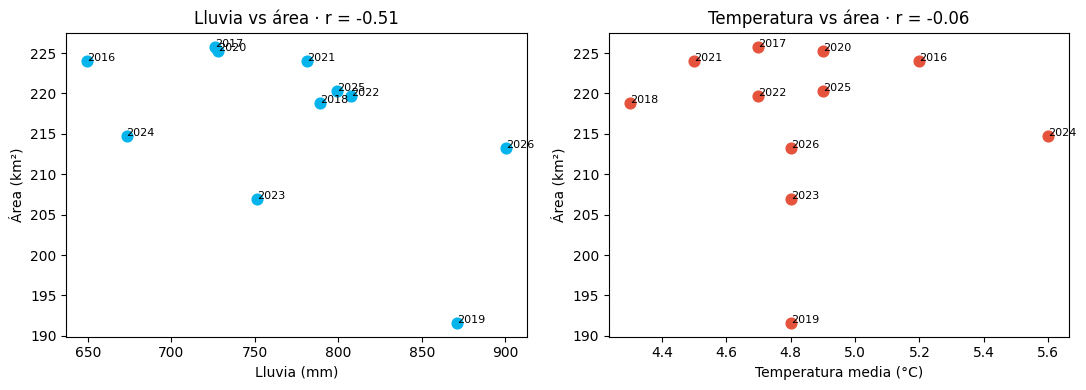

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(df["lluvia_CHIRPS_mm"], df["area_km2"], color="#05B4EB", s=60)
ax[0].set_xlabel("Lluvia (mm)"); ax[0].set_ylabel("Área (km²)")
ax[0].set_title(f"Lluvia vs área · r = {df['lluvia_CHIRPS_mm'].corr(df['area_km2']):.2f}")
ax[1].scatter(df["temp_C"], df["area_km2"], color="#E5533D", s=60)
ax[1].set_xlabel("Temperatura media (°C)"); ax[1].set_ylabel("Área (km²)")
ax[1].set_title(f"Temperatura vs área · r = {df['temp_C'].corr(df['area_km2']):.2f}")
for i, r in df.iterrows():
    ax[0].annotate(int(r["anio"]), (r["lluvia_CHIRPS_mm"], r["area_km2"]), fontsize=8)
    ax[1].annotate(int(r["anio"]), (r["temp_C"], r["area_km2"]), fontsize=8)
plt.tight_layout(); plt.show()

### Paso 10 · Interpreta (responde en tu ficha)
1. ¿En qué año el lago tuvo **menos** superficie? ¿Ese año (o el anterior) fue un año de **El Niño** o de lluvias bajo lo normal?
2. ¿La temperatura muestra una **tendencia** a subir? ¿Qué le pasa a la evaporación cuando sube la temperatura?
3. Mira la columna **P − E**: ¿en qué años el lago "gastó" más agua de la que recibió?
4. ¿CHIRPS y ERA5‑Land cuentan la misma historia? ¿Cuál usarías y por qué?
5. Además del clima, ¿qué otros factores del **balance hídrico** podrían explicar los cambios? (pista: represa de Upamayo, extracciones, totorales).

> ⚠️ Correlación no es causalidad: con 11 años de datos solo podemos plantear **hipótesis**.

### Paso 11 · Guardar la tabla para tu informe

In [ ]:
df.to_csv("Chinchaycocha_2016_2026.csv", index=False)
from google.colab import files
files.download("Chinchaycocha_2016_2026.csv")